# 01 · Primeros pasos con gwsim

**Objetivo:** comprobar el entorno, generar 10 señales de dos maneras (con la línea de órdenes y desde Python) y entender qué hay dentro del fichero HDF5 que produce gwsim.

**Requisitos:** el entorno `gwsim` activo como kernel de este notebook (ver `docs/ENTORNO.md`). El paquete de PSD `psd_pack_o3b.npz` en la raíz del repositorio es recomendable; si no está, el notebook usa ruido analítico y lo avisa.

**Tiempo aproximado:** 1–2 minutos en CPU.

Ejecuta las celdas en orden, de arriba abajo.

## Preparación

Esta celda hace tres cosas:

1. Localiza la raíz del repositorio (este notebook está en `tutorials/`) y la añade a `sys.path`, para poder hacer `import gwsim` sin instalar nada.
2. Busca el paquete de PSD. `PSD_PACK` es la ruta del paquete; si es relativa, se interpreta respecto a la raíz del repositorio. Si no existe, se usa ruido analítico (curvas de diseño de los detectores) y aparece un aviso.
3. Crea la fuente de ruido `noise`, que da las PSD de cada señal.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')

from gwsim.noise import PsdPackNoise, AnalyticNoise
O3B_GPS = [1256655618.0, 1269363618.0]
noise = PsdPackNoise(pack_path, ['train']) if USE_PACK else AnalyticNoise(O3B_GPS)

OUT = ROOT / 'tutorials' / 'salidas'
OUT.mkdir(exist_ok=True)
COLORS = {'H1': '#d55e00', 'L1': '#0072b2', 'V1': '#009e73'}  # paleta Okabe-Ito, legible con daltonismo
print('Raíz del repositorio:', ROOT)
print('Ruido:', 'paquete de PSD de O3b' if USE_PACK else 'analítico')

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


Raíz del repositorio: /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim
Ruido: paquete de PSD de O3b


## 1. Comprobar el entorno

gwsim se apoya en **PyCBC** (formas de onda, proyección sobre los detectores, PSD, filtros) y en **LALSuite** (la biblioteca de la colaboración LIGO-Virgo-KAGRA que hay debajo). Las versiones deben ser las de `environment.yml`: con ellas se verificó que gwsim reproduce los datos de referencia bit a bit (`docs/VALIDEZ.md`).

Si aparece un aviso sobre `pkg_resources`, es inofensivo.

In [2]:
import pycbc, lal, h5py, scipy, matplotlib
import gwsim
for name, module in [('gwsim', gwsim), ('pycbc', pycbc), ('lalsuite', lal), ('numpy', np),
                     ('scipy', scipy), ('h5py', h5py), ('matplotlib', matplotlib)]:
    print(f'{name:<11} {module.__version__}')

gwsim       0.1.0
pycbc       2.9.0
lalsuite    7.7.1
numpy       2.2.6
scipy       1.15.3
h5py        3.16.0
matplotlib  3.10.9


## 2. Generar 10 señales con la línea de órdenes

La forma normal de usar gwsim es la orden `python -m gwsim generate`, que lee una configuración JSON y escribe un fichero HDF5. Aquí la lanzamos desde el notebook con `!` (IPython sustituye `{variable}` por su valor).

- Con el paquete de PSD usamos `configs/default.json`: la configuración por defecto, la validada.
- Sin paquete, `configs/example_custom_prior.json`, que usa ruido analítico.

gwsim **nunca sobrescribe** un fichero, así que primero borramos la salida de una ejecución anterior de este notebook.

In [3]:
out_cli = OUT / '00_cli.h5'
if out_cli.exists():
    out_cli.unlink()
config = ROOT / 'configs' / ('default.json' if USE_PACK else 'example_custom_prior.json')
!cd {ROOT} && python -m gwsim generate --config {config} --output {out_cli} --n-samples 10

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
AVISO: M_tot puede bajar a 10.0 < 16: algunas formas de onda pueden no generarse (esas filas quedarán con status = 2)
Creado /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/00_cli.h5: 10 filas
10 filas pendientes de 10; 1 proceso(s)
1/10 (hechas 1, fallidas 0); 4 s
2/10 (hechas 2, fallidas 0); 4 s
3/10 (hechas 3, fallidas 0); 5 s
4/10 (hechas 4, fallidas 0); 6 s
5/10 (hechas 5, fallidas 0); 6 s
6/10 (hechas 6, fallidas 0); 7 s
7/10 (hechas 7, fallidas 0); 7 s
8/10 (hechas 8, fallidas 0); 8 s
9/10 (hechas 9, fallidas 0); 9 s
10/10 (hechas 10, fallidas 0); 9 s
Terminado: /afs/ciemat.es/user/v/vserran

Cada línea `k/10 (hechas …, fallidas …)` indica el progreso. Si aparece un `AVISO` sobre M_tot < 16, es normal con el prior por defecto: algunas masas muy pequeñas podrían no generarse, y esas filas se marcarían como fallidas sin parar el resto.

`gwsim info` resume el fichero:

In [4]:
!cd {ROOT} && python -m gwsim info {out_cli}

/afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/00_cli.h5: gwsim 0.1.0, creado 2026-11-23T16:58:25+00:00
  modo snr, ruido psd_pack, click_free True, seed 20261123
  filas 10: hechas 10, fallidas 0, pendientes 0
  X: (10, 3, 16384) float32
  total_mass: mín 61.28, mediana 96.28, máx 173.4
  final_network_snr: mín 10.57, mediana 15.99, máx 20.78
  final_distance: mín 161.8, mediana 985, máx 3389
  AVISO: M_tot puede bajar a 10.0 < 16: algunas formas de onda pueden no generarse (esas filas quedarán con status = 2)


## 3. Generar señales desde Python

Desde Python se puede generar una fila con `simulate_row`. Es útil para experimentar o para mirar pasos intermedios. Necesita:

- `Physics()`: los objetos de la física por defecto (forma de onda, proyector, procesador), construidos una vez;
- los parámetros de la fuente (masas en masas solares, espines alineados adimensionales, ángulos en radianes);
- un GPS (el centro de la ventana de 4 s) y las PSD de ese instante, que da `noise`;
- dos semillas: `placement_seed` decide dónde cae la señal dentro de la ventana y `gaussian_seed` decide la realización del ruido;
- la SNR de red objetivo: gwsim ajusta la distancia para conseguirla.

Generamos 3 señales con masas distintas.

In [5]:
from gwsim.recipe import Physics, RowOptions, simulate_row

phys = Physics()
opts = RowOptions(physics=phys, mode='snr', outputs=('X',))
rng = np.random.default_rng(2026)
assignment = noise.assign(3, rng)          # 3 recortes de ruido: block_id y GPS de cada uno

fuentes = [(30.0, 25.0), (50.0, 12.0), (70.0, 65.0)]
X_py, metas = [], []
for k, (m1, m2) in enumerate(fuentes):
    params = dict(mass_1=m1, mass_2=m2, spin_1z=0.2, spin_2z=-0.1,
                  inclination=0.5, ra=2.0, dec=0.3, polarization_angle=1.0)
    psds = noise.psds(assignment['block_id'][k], phys.config)
    out, meta = simulate_row(params, assignment['gps'][k], psds, placement_seed=100 + k,
                             gaussian_seed=200 + k, target_snr=15.0, opts=opts)
    X_py.append(out['X'])
    metas.append(meta)
    print(f'm1={m1:5.1f} m2={m2:5.1f}  SNR de red={meta["final_network_snr"]:.3f}  '
          f'distancia={meta["final_distance"]:.0f} Mpc  banda de arranque={meta["band_f_lower"]:.0f} Hz')

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


m1= 30.0 m2= 25.0  SNR de red=15.000  distancia=1655 Mpc  banda de arranque=15 Hz
m1= 50.0 m2= 12.0  SNR de red=15.000  distancia=841 Mpc  banda de arranque=15 Hz
m1= 70.0 m2= 65.0  SNR de red=15.000  distancia=2052 Mpc  banda de arranque=15 Hz


La SNR sale muy cerca de 15 en las tres: gwsim mide la SNR a 1000 Mpc y reescala la distancia (la amplitud va como 1/d). Por eso las fuentes más masivas, que son más intensas, quedan más lejos. El tutorial 02 lo explica en detalle.

## 4. Leer el fichero HDF5

`gwsim.load` devuelve un diccionario con las salidas pedidas (aquí `X`) y **todos** los metadatos, solo de las filas hechas (`status == 1`).

In [6]:
d = gwsim.load(out_cli, outputs=('X',))
print('X:', d['X'].shape, d['X'].dtype)
print('y:', d['y'].shape, '-> columnas [chirp_mass, total_mass, chi_eff]')
print('Metadatos disponibles:')
print(sorted(k for k in d if k not in ('X',)))

X: (10, 3, 16384) float32
y: (10, 3) -> columnas [chirp_mass, total_mass, chi_eff]
Metadatos disponibles:
['actual_geocentric_time', 'align_residual_rad', 'band_f_lower', 'band_taper_end_hz', 'block_id', 'chi_eff', 'chirp_mass', 'dec', 'distance_input', 'edge_samples_H1', 'edge_samples_L1', 'edge_samples_V1', 'error', 'final_distance', 'final_network_snr', 'full_network_duration', 'gaussian_seed', 'gaussian_seed_H1', 'gaussian_seed_L1', 'gaussian_seed_V1', 'gps', 'inclination', 'is_truncated', 'mass_1', 'mass_2', 'noise_crop_id', 'noise_split', 'placement_offset_s', 'placement_seed', 'polarization_angle', 'q', 'ra', 'reference_network_snr', 'required_final_duration', 'row_index', 'snr_H1', 'snr_L1', 'snr_V1', 'spin_1z', 'spin_2z', 'status', 'target_network_snr', 'total_mass', 'y']


### Estructura de X

`X` tiene forma `(señales, 3, 16384)`:

- el eje 1 son los detectores, en el orden H1 (Hanford), L1 (Livingston) y V1 (Virgo);
- el eje 2 son 16384 muestras = 4 s a 4096 Hz.

Cada canal está blanqueado, filtrado a 30–1024 Hz y normalizado (z-score: media 0 y desviación 1), así que es adimensional. Con SNR 10–25 la señal casi nunca se ve a simple vista en `X`: está enterrada en el ruido. Por eso hacen falta métodos estadísticos para detectarla.

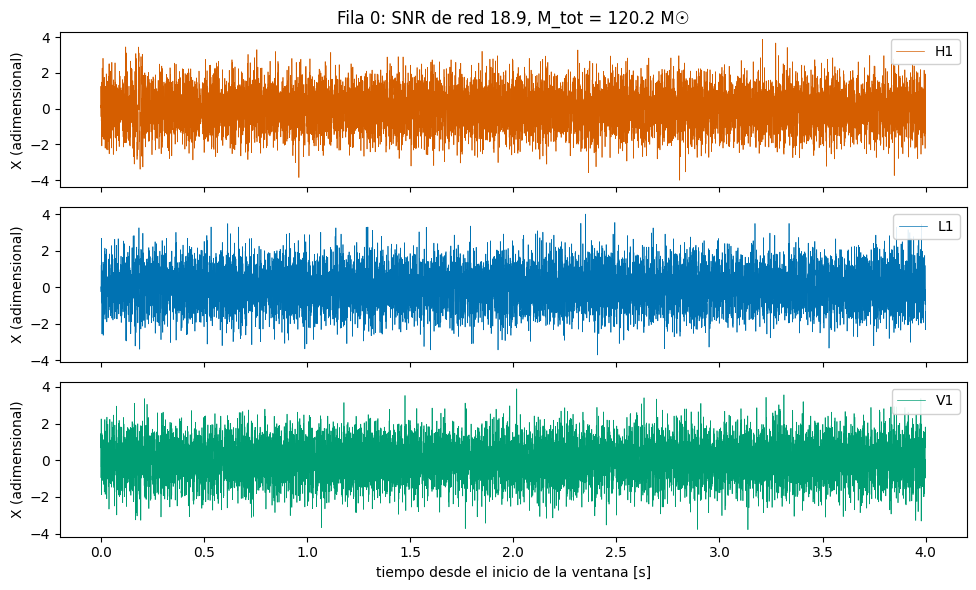

In [7]:
t = np.arange(d['X'].shape[-1]) / phys.config.sampling_frequency
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for ax, (j, ifo) in zip(axes, enumerate(['H1', 'L1', 'V1'])):
    ax.plot(t, d['X'][0, j], color=COLORS[ifo], lw=0.5, label=ifo)
    ax.set_ylabel('X (adimensional)')
    ax.legend(loc='upper right', framealpha=0.9)
axes[-1].set_xlabel('tiempo desde el inicio de la ventana [s]')
axes[0].set_title(f'Fila 0: SNR de red {d["final_network_snr"][0]:.1f}, M_tot = {d["total_mass"][0]:.1f} M☉')
plt.tight_layout()
plt.show()

### Metadatos por fila

Cada fila guarda sus parámetros, la SNR (de red y por detector), la distancia final, el instante de coalescencia, el bloque de ruido, las semillas… (lista completa en `docs/SALIDAS.md`). Por ejemplo:

In [8]:
for i in range(len(d['row_index'])):
    print(f'fila {d["row_index"][i]}: m1={d["mass_1"][i]:5.1f} m2={d["mass_2"][i]:5.1f} '
          f'chi_eff={d["chi_eff"][i]:+.2f}  SNR={d["final_network_snr"][i]:5.2f} '
          f'(H1 {d["snr_H1"][i]:4.1f}, L1 {d["snr_L1"][i]:4.1f}, V1 {d["snr_V1"][i]:4.1f})  '
          f'd={d["final_distance"][i]:5.0f} Mpc  bloque={d["block_id"][i]}')

fila 0: m1= 74.6 m2= 45.6 chi_eff=+0.60  SNR=18.86 (H1 15.0, L1  8.7, V1  7.5)  d=  886 Mpc  bloque=M116_RB_00024
fila 1: m1= 31.0 m2= 30.3 chi_eff=+0.27  SNR=17.18 (H1  5.4, L1  8.0, V1 14.2)  d=  408 Mpc  bloque=M116_RB_00254
fila 2: m1= 62.0 m2=  7.7 chi_eff=+0.31  SNR=10.57 (H1  1.6, L1 10.0, V1  3.0)  d=  162 Mpc  bloque=M116_RB_00187
fila 3: m1= 50.3 m2= 46.4 chi_eff=-0.65  SNR=15.83 (H1  8.9, L1 13.0, V1  1.4)  d=  606 Mpc  bloque=M116_RB_00069
fila 4: m1= 84.1 m2= 28.5 chi_eff=+0.44  SNR=15.68 (H1 11.7, L1 10.4, V1  0.3)  d= 1922 Mpc  bloque=M116_RB_00261
fila 5: m1= 79.6 m2=  7.3 chi_eff=+0.48  SNR=11.03 (H1  6.2, L1  8.5, V1  3.3)  d=  997 Mpc  bloque=M116_RB_00235
fila 6: m1= 69.8 m2= 26.1 chi_eff=-0.13  SNR=20.78 (H1 12.1, L1 16.7, V1  2.6)  d=  973 Mpc  bloque=M116_RB_00073
fila 7: m1= 88.4 m2= 85.0 chi_eff=-0.69  SNR=14.66 (H1 10.3, L1 10.4, V1  0.5)  d= 3389 Mpc  bloque=M116_RB_00184
fila 8: m1= 56.2 m2= 32.3 chi_eff=-0.33  SNR=17.12 (H1 11.3, L1 12.7, V1  2.1)  d= 1101 

Observa que la SNR de red es la suma en cuadratura de las tres: ρ_red² = ρ_H1² + ρ_L1² + ρ_V1². V1 suele aportar menos porque Virgo era menos sensible que los LIGO en O3b.

Para leer con h5py directamente (útil con ficheros grandes), mira `docs/SALIDAS.md` y el tutorial 06.

**Siguiente:** `02_anatomia_de_una_senal.ipynb`.